# Lab 2 — What Did the Campaign Deliver?
Name: Katerina | Group: KM-41

## Setup

In [28]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [18]:
commercials.head()

,ad_airing_id,telecast_id,network_code,start_ts,length_sec,pod_id,pod_position,brand,category
0,70000001,1017215,HIST,2024-10-01 06:07:17,30,1017215-1,1,AUTO_09,AUTO
1,70000002,1017215,HIST,2024-10-01 06:07:47,30,1017215-1,2,PROMO_02,PROMO
2,70000003,1012667,FOOD,2024-10-01 06:08:14,30,1012667-1,1,PROMO_02,PROMO
3,70000004,1017215,HIST,2024-10-01 06:08:17,30,1017215-1,3,PROMO_03,PROMO
4,70000005,1012667,FOOD,2024-10-01 06:08:44,30,1012667-1,2,PHARMA_07,PHARMA


## Task 1.1 — Size

In [24]:
print("Spots:", len(commercials))
print("Pods:", (commercials['pod_id'].nunique()))
print("Brands:", (commercials['brand'].nunique()))
print("Categories:", (commercials['category'].nunique()))
brand_a=commercials[commercials['brand']=='BRAND_A']

print("BRAND_A spots:", len(brand_a))
# table: BRAND_A spots by network

table = brand_a.groupby('network_code').size().reset_index(name='spots_count')
print(table)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300
  network_code  spots_count
0          ABC           29
1        BRAVO           33
2          CBS           22
3          FNC           40
4         FOOD           33
5          FOX           13
6           FX           38
7         HGTV           39
8         HIST           37
9          NBC           16


## Task 1.2 — Ad load

In [25]:
# table: ad minutes per hour by network
commercials['hour'] = commercials['start_ts'].dt.floor('h')
hourly_ad_seconds = commercials.groupby(['network_code', 'hour'])['length_sec'].sum().reset_index()
load_minutes = hourly_ad_seconds.groupby('network_code')['length_sec'].mean().div(60).reset_index(name='ad_minutes_per_hour')
display(load_minutes)
heaviest = load_minutes.loc[load_minutes['ad_minutes_per_hour'].idxmax()]['network_code']
print("Heaviest ad load:", heaviest)

,network_code,ad_minutes_per_hour
0,ABC,11.843123
1,BRAVO,13.434189
2,CBS,12.136417
3,FNC,15.638627
4,FOOD,13.113710
5,FOX,11.785714
6,FX,12.915459
7,HGTV,13.343800
8,HIST,13.205788
9,NBC,11.822742


Heaviest ad load: FNC


**Answer:** why broadcast networks have hours without national ads.
Broadcast networks (such as CBS, NBC, ABC, FOX) have hours without national ads because a portion of their broadcast schedule is allocated to local stations (local-station hours). During these blocks, ad breaks are reserved and sold locally by affiliated local stations rather than the national network, which is why no national commercials appear in the dataset during those hours.

## Task 1.3 — Price everything

In [26]:
spots = commercials.merge(
    programs[["telecast_id", "program_name"]].drop_duplicates("telecast_id"),
    on="telecast_id", how="left")

is_prog = rate_card["program_name"].fillna("").str.strip() != ""
prog_rows = (rate_card[is_prog][["network_code", "program_name", "daypart", "cost_30s_usd"]]
             .rename(columns={"daypart": "prog_daypart", "cost_30s_usd": "prog_cost"}))
time_rows = rate_card[~is_prog].copy()
spots = spots.merge(prog_rows, on=["network_code", "program_name"], how="left")

def to_min(s):
    h, m = s.split(":")
    return int(h) * 60 + int(m) - 360

time_rows["start_min"] = time_rows["start_time"].map(to_min)
time_rows["end_min"] = time_rows["end_time"].map(to_min)
time_rows = time_rows.explode("weekdays")
time_rows["weekday"] = time_rows["weekdays"].astype(int)
time_rows = time_rows[["network_code", "weekday", "start_min", "end_min", "daypart", "cost_30s_usd"]]

bc = spots["start_ts"] - pd.Timedelta(hours=6)
spots["weekday"] = bc.dt.weekday
spots["minute"] = bc.dt.hour * 60 + bc.dt.minute + bc.dt.second / 60
m = spots[["ad_airing_id", "network_code", "weekday", "minute"]].merge(
    time_rows, on=["network_code", "weekday"])
m = m[(m["start_min"] <= m["minute"]) & (m["minute"] < m["end_min"])]
m = m[["ad_airing_id", "daypart", "cost_30s_usd"]].rename(
    columns={"daypart": "time_daypart", "cost_30s_usd": "time_cost"})
assert m["ad_airing_id"].is_unique
spots = spots.merge(m, on="ad_airing_id", how="left")

spots["from_program"] = spots["prog_cost"].notna()
spots["selling_daypart"] = spots["prog_daypart"].where(spots["from_program"], spots["time_daypart"])
spots["cost_30s"] = spots["prog_cost"].where(spots["from_program"], spots["time_cost"])
spots["cost"] = spots["cost_30s"] * spots["length_sec"] / 30
assert len(spots) == len(commercials)

print("Spots without a price:", int(spots["cost"].isna().sum()))
g = spots.groupby("network_code")
tab = pd.DataFrame({
    "value_usd_M": g["cost"].sum() / 1e6,
    "share_from_program_rows": spots[spots["from_program"]].groupby("network_code")["cost"].sum()
                               / g["cost"].sum(),
}).fillna(0).round({"value_usd_M": 1, "share_from_program_rows": 3})
print(tab)

Spots without a price: 0
              value_usd_M  share_from_program_rows
network_code                                      
ABC                 708.8                    0.432
BRAVO                25.3                    0.000
CBS                 818.8                    0.230
FNC                 315.8                    0.000
FOOD                 42.1                    0.000
FOX                 696.2                    0.835
FX                   42.5                    0.000
HGTV                 58.1                    0.000
HIST                 40.1                    0.000
NBC                 724.3                    0.342


## Task 2.1 — Delivery

In [29]:

PID, W = "respondent_id", "weight"
A_AGE, A_SEX, FEMALE = "age", "sex", "F"
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]

va = viewer_attributes
age = va[va["attr_id"] == 300].groupby(PID)["value"].first().rename(A_AGE)
sex = (va[va["attr_id"].isin([201, 202])].groupby(PID)["attr_id"].first()
       .map({201: "M", 202: "F"}).rename(A_SEX))
rl_ids = daily_weights.loc[daily_weights["resp_type"].isin(["R", "L"]), PID].drop_duplicates()
persons = rl_ids.to_frame().merge(age, on=PID, how="left").merge(sex, on=PID, how="left")
print("R/L persons without age:", int(persons[A_AGE].isna().sum()))

dw = daily_weights[daily_weights["resp_type"].isin(["R", "L"])].merge(persons, on=PID, how="left")
dw["bdate"] = pd.to_datetime(dw["broadcast_date"]).dt.date
dw["is_a1849"] = dw[A_AGE].between(18, 49)
mw = dw.groupby(PID)[W].mean().rename("mw").reset_index().merge(persons, on=PID, how="left")
mw["is_a1849"] = mw[A_AGE].between(18, 49)
den_day = pd.DataFrame({"p2": dw.groupby("bdate")[W].sum(),
                        "a1849": dw[dw["is_a1849"]].groupby("bdate")[W].sum()})
n_day = dw.groupby("bdate")[PID].nunique()

a = spots[spots["brand"] == "BRAND_A"].copy()
a["bdate"] = (a["start_ts"] - pd.Timedelta(hours=6)).dt.date
vv = viewings[viewings[PID].isin(persons[PID])]
parts = []
for net, gn in a.groupby("network_code"):
    vn = vv[vv["network_code"] == net]
    s_arr, e_arr, p_arr = vn["start_ts"].values, vn["end_ts"].values, vn[PID].values
    for r in gn.itertuples():
        t = np.datetime64(r.start_ts)
        mask = (s_arr <= t) & (t < e_arr)
        parts.append(pd.DataFrame({"ad_airing_id": r.ad_airing_id, PID: np.unique(p_arr[mask])}))
exp = pd.concat(parts, ignore_index=True)
exp = exp.merge(a[["ad_airing_id", "network_code", "bdate", "cost"]], on="ad_airing_id")
exp = exp.merge(dw[[PID, "bdate", W, "is_a1849", A_AGE, A_SEX]], on=[PID, "bdate"])
print("Exposure rows:", len(exp))

def sub(e, aud):
    return e if aud == "p2" else e[e["is_a1849"]]

def spot_table(e, aud):
    d = sub(e, aud)
    t = a.set_index("ad_airing_id")[["network_code", "bdate", "cost"]].copy()
    t["imp"] = d.groupby("ad_airing_id")[W].sum()
    t["imp"] = t["imp"].fillna(0)
    t["rating"] = t["imp"] / t["bdate"].map(den_day[aud]) * 100
    return t

def reach(e, aud):
    ids = sub(e, aud)[PID].unique()
    m_ = mw if aud == "p2" else mw[mw["is_a1849"]]
    return m_[m_[PID].isin(ids)]["mw"].sum() / m_["mw"].sum() * 100

res = {}
for aud in ["p2", "a1849"]:
    t = spot_table(exp, aud)
    imp, grp, rch = t["imp"].sum(), t["rating"].sum(), reach(exp, aud)
    res[aud] = dict(imp=imp, grp=grp, reach=rch, freq=grp / rch)

p, q = res["p2"], res["a1849"]
print("P2+ impressions (M):", round(p["imp"] / 1e6, 1))
print("P2+ GRPs:", round(p["grp"], 1))
print("P2+ reach (%):", round(p["reach"], 1))
print("P2+ average frequency:", round(p["freq"], 2))
print("A18-49 impressions (M):", round(q["imp"] / 1e6, 1))
print("A18-49 GRPs:", round(q["grp"], 1))
print("A18-49 reach (%):", round(q["reach"], 1))
print("A18-49 average frequency:", round(q["freq"], 2))

R/L persons without age: 0
Exposure rows: 11289
P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.03
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 1.98


## Task 2.2 — Frequency distribution

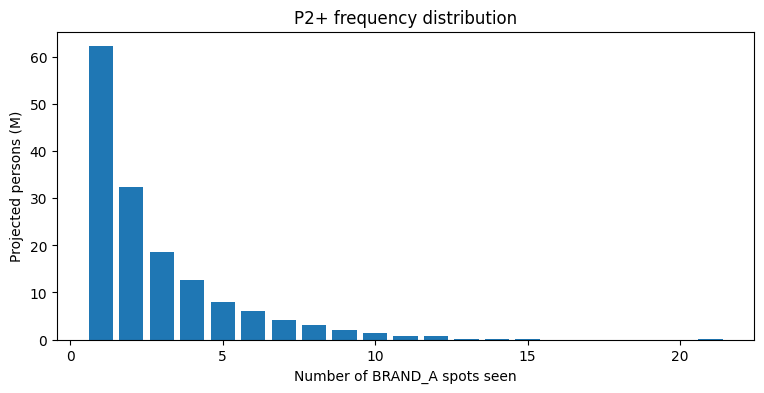

Share of impressions at 5+ exposures: 0.444


In [30]:
# plot: projected persons (M) by number of spots seen
per_p = exp.groupby(PID).agg(n=("ad_airing_id", "nunique"), imp=(W, "sum")).reset_index()
per_p = per_p.merge(mw[[PID, "mw"]], on=PID)
dist = per_p.groupby("n")["mw"].sum() / 1e6
plt.figure(figsize=(9, 4))
plt.bar(dist.index, dist.values)
plt.xlabel("Number of BRAND_A spots seen"); plt.ylabel("Projected persons (M)")
plt.title("P2+ frequency distribution"); plt.show()
share5 = per_p.loc[per_p["n"] >= 5, "imp"].sum() / per_p["imp"].sum()
print("Share of impressions at 5+ exposures:", round(share5, 3))


**Answer:** is the average frequency a fair summary?
No, the average frequency is not a fair summary because the frequency distribution is highly skewed (right-skewed). As the plot shows, the vast majority of reached people see only 1, 2, or 3 spots, while a small group of heavy viewers see many more (up to 20+ spots). The average is pulled up by these heavy viewers, so it does not represent the typical experience of most audience members.

## Task 2.3 — On target?

In [31]:
share_t = res["a1849"]["imp"] / res["p2"]["imp"]
print("Share of impressions on A18-49:", round(share_t, 3))

Share of impressions on A18-49: 0.194


**Answer:** over- or under-delivery against the target, and which networks explain it.

The campaign experienced a significant under-delivery against its target. While adults 18–49 (A18-49) make up about 42% of the total population, they received only 19.4% of the campaign's total impressions. This under-delivery is explained by the network selection and media placement choices—specifically, placing spots heavily on older-skewing networks (such as traditional broadcast networks or news channels like FNC) where the viewership profile is predominantly older than 49, rather than concentrating spots on younger cable and entertainment networks

## Task 3.1 — Cost

In [32]:
cost = a["cost"].sum()
print("Campaign cost (USD):", round(cost))
print("P2+ CPM (USD):", round(cost / (res["p2"]["imp"] / 1000), 2))
print("P2+ CPP (USD):", round(cost / res["p2"]["grp"]))
print("A18-49 CPM (USD):", round(cost / (res["a1849"]["imp"] / 1000), 2))
print("A18-49 CPP (USD):", round(cost / res["a1849"]["grp"]))


Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [38]:
# table: spots, cost, impressions, P2+ CPM and A18-49 CPM by network
sp, st_ = spot_table(exp, "p2"), spot_table(exp, "a1849")
byn = pd.DataFrame({
    "spots": a.groupby("network_code").size(),
    "cost": a.groupby("network_code")["cost"].sum(),
    "p2_imp_M": sp.groupby("network_code")["imp"].sum() / 1e6,
    "a1849_imp_M": st_.groupby("network_code")["imp"].sum() / 1e6,
})
byn["p2_cpm"] = byn["cost"] / (byn["p2_imp_M"] * 1000)
byn["a1849_cpm"] = byn["cost"] / (byn["a1849_imp_M"] * 1000)
print(byn.round({"cost": 0, "p2_imp_M": 1, "a1849_imp_M": 1, "p2_cpm": 2, "a1849_cpm": 2}))

              spots       cost  p2_imp_M  a1849_imp_M  p2_cpm  a1849_cpm
network_code                                                            
ABC              29  1625700.0      94.2         17.0   17.26      95.69
BRAVO            33    49610.0       5.1          2.8    9.76      17.61
CBS              22  1488700.0      89.0         13.7   16.73     108.72
FNC              40   526300.0      57.8          2.7    9.11     193.70
FOOD             33    96620.0       9.5          3.0   10.19      32.29
FOX              13  2434700.0      76.3         18.4   31.93     132.03
FX               38    92200.0       8.5          5.6   10.82      16.61
HGTV             39   230000.0      24.7          7.6    9.33      30.45
HIST             37    79640.0      12.3          2.5    6.46      32.05
NBC              16   796800.0      41.4          7.8   19.23     101.72


**Answer:** where the money went. The majority of the budget was spent on major broadcast networks (such as FOX, ABC, and CBS) due to their high commercial costs and extensive reach, even though they had fewer total spots compared to cable networks.

the cheapest networks for the target. Cheapest networks for the target (A18-49): Based on the a1849_cpm column, the cheapest networks to reach the target audience are FX (lowest CPM of 16.61) and BRAVO (17.61), as well as other cable networks like FOOD and HGTV, which deliver a much higher concentration of the target demographic per dollar spent compared to traditional broadcast or news networks (like FNC or FOX).

## Task 3.3 — Guarantee

In [34]:
GUAR = 150
met = res["p2"]["grp"] >= GUAR
owed = max(0.0, GUAR - res["p2"]["grp"])
cpp = cost / res["p2"]["grp"]
print("Guarantee met:", bool(met))
print("Make-good GRPs owed:", round(owed, 1))
print("Value of make-goods (USD):", round(owed * cpp))


Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [35]:
eb, es = exp[exp["network_code"].isin(BIG)], exp[exp["network_code"].isin(SMALL)]
rb, rs, rw = reach(eb, "p2"), reach(es, "p2"), reach(exp, "p2")
ov = rb + rs - rw
ov_ind = rb * rs / 100
cost_big = a[a["network_code"].isin(BIG)]["cost"].sum()
cost_small = a[a["network_code"].isin(SMALL)]["cost"].sum()
print("Reach, big networks (%):", round(rb, 1))
print("Reach, small networks (%):", round(rs, 1))
print("Reach, whole campaign (%):", round(rw, 1))
print("Overlap (%):", round(ov, 1))
print("Overlap if independent (%):", round(ov_ind, 1))
print("Reach added by small networks (points):", round(rw - rb, 1))
print("Cost per added reach point, small (USD):", round(cost_small / (rw - rb)))
print("Cost per reach point, big (USD):", round(cost_big / rb))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** why reach does not add? Reach does not sum up because different networks reach overlapping audiences. Many of the same people watch both big and small networks, so simply adding individual reach percentages together would double-count these viewers.

what the overlap says? The actual overlap (8.7%) is higher than what would be expected if the two groups were independent (4.9%). This indicates that viewers of small networks are more likely than average to have been reached by the big networks, reflecting common television viewing habits (heavy TV viewers tend to watch a wide variety of channels).

was the small-network money well spent? Was the small-network money well spent: Yes, the money spent on small networks was well spent because the cost per added reach point for small networks (148,706) is lower than the cost per reach point for big networks (172,456), making them a cost-effective way to incrementally increase total campaign reach.

## Task 5 — How sure are we?

In [36]:
# table: median panelists per spot and median relative SE, by network
allspots = a["ad_airing_id"]
n_pan = exp.groupby("ad_airing_id")[PID].nunique().reindex(allspots, fill_value=0)
t5 = spot_table(exp, "p2")
t5["panelists"] = n_pan
p = t5["rating"] / 100
t5["n"] = t5["bdate"].map(n_day)
t5["se"] = np.sqrt(p * (1 - p) / t5["n"]) * 100
t5["rel_se"] = t5["se"] / t5["rating"].replace(0, np.nan)
t5["group"] = np.where(t5["network_code"].isin(BIG), "big", "small")
print(t5.groupby("network_code").agg(median_panelists=("panelists", "median"),
                                      median_rel_se=("rel_se", "median")).round(3))
print("Spots seen by no panelist:", int((t5["panelists"] == 0).sum()))
print("Median relative SE, big networks:", round(t5.loc[t5["group"] == "big", "rel_se"].median(), 3))
print("Median relative SE, small networks:", round(t5.loc[t5["group"] == "small", "rel_se"].median(), 3))
w1834 = exp[(exp[A_SEX] == FEMALE) & exp[A_AGE].between(18, 34)]
seen_w = w1834["ad_airing_id"].nunique()
print("W18-34 zero-cell spots:", int(len(allspots) - seen_w))



              median_panelists  median_rel_se
network_code                                 
ABC                       57.0          0.123
BRAVO                      3.0          0.540
CBS                       69.0          0.113
FNC                       31.0          0.164
FOOD                       5.0          0.423
FOX                      145.0          0.080
FX                         5.5          0.423
HGTV                      11.0          0.301
HIST                       5.0          0.460
NBC                       68.5          0.115
Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:**
What a zero rating means? A zero rating (or a zero-cell) does not necessarily mean that literally no one in the entire population watched the spot. Instead, it means that no panelists in the sample happened to record viewing that specific spot, which is a common artifact of small sample sizes and niche target groups (like W18-34 on small networks).

What you would tell the client? I would advise the client to exercise extreme caution when evaluating ratings and performance metrics for individual spots-especially on smaller networks or narrow target demographics (where 171 out of 300 spots have zero viewers in the sample). While the aggregated campaign numbers are relatively stable, spot-level data for small networks suffers from high sampling error and unreliability due to sparse panelist data, meaning individual zero ratings should not be interpreted as absolute proof of zero audience.

## Bonus

**Answer:** your proposed change and the numbers behind it.